
**Stochastic Variational Inference for LDA model**








In [1]:
import time
import numpy
import matplotlib.pyplot as plt
import numpy as np
import scipy.special as sp_spec
import scipy.stats as sp_stats

**Generate data**



The cell below generates data for the LDA model. Note, for simplicity, we are using N_d = N for all d.

In [2]:
import torch
import torch.distributions as t_dist

def generate_data(D, N, K, W, eta, alpha):
    """
    Torch implementation for generating data using the LDA model. Faster for larger datasets.
    D = number of documents
    N = number of words in each document
    K = number of topics
    W = number of words in vocabulary
    """
    # sample K topics
    beta_dist = t_dist.Dirichlet(torch.from_numpy(eta))
    beta = beta_dist.sample([K])  # size K x W

    # sample document topic distribution
    theta_dist = t_dist.Dirichlet(torch.from_numpy(alpha))
    theta = theta_dist.sample([D]) # size D x K

    # sample word to topic assignment
    z_dist = t_dist.OneHotCategorical(probs=theta)
    z = z_dist.sample([N])
    z = torch.einsum("ndk->dnk", z)

    # sample word from selected topics
    beta_select = torch.einsum("kw, dnk -> dnw", beta, z)
    w_dist = t_dist.OneHotCategorical(probs=beta_select)
    w = w_dist.sample([1])

    w = w.reshape(D, N, W)

    return w.numpy(), z.numpy(), theta.numpy(), beta.numpy()

torch.manual_seed(1)

D_sim = 1000
N_sim = 500
K_sim = 2
W_sim = 10

eta_sim = np.ones(W_sim)
eta_sim[3] = 0.0001     # Expect word 3 to not appear in data
eta_sim[1] = 3.         # Expect word 1 to be most common in data
alpha_sim = np.ones(K_sim) * 1.0
w0, z0, theta0, beta0 = generate_data(D_sim, N_sim, K_sim, W_sim, eta_sim, alpha_sim)
w_cat = w0.argmax(axis=-1)  # remove one hot encoding
unique_z, counts_z = numpy.unique(z0[0, :], return_counts=True)
unique_w, counts_w = numpy.unique(w_cat[0, :], return_counts=True)

# Sanity checks for data generation
print(f"Average z of each document should be close to theta of document. \n Theta of doc 0: {theta0[0]}"
      f" \n Mean z of doc 0: {z0[0].mean(axis=0)}")
print(f"Beta of topic 0: {beta0[0]}")
print(f"Beta of topic 1: {beta0[1]}")
print(f"Word to topic assignment, z, of document 0: {z0[0, 0:10]}")
print(f"Observed words, w, of document 0: {w_cat[0, 0:10]}")
print(f"Unique words and count of document 0: {[f'{u}: {c}' for u, c in zip(unique_w, counts_w)]}")

Average z of each document should be close to theta of document. 
 Theta of doc 0: [0.13975145 0.86024855] 
 Mean z of doc 0: [0.152 0.848]
Beta of topic 0: [1.34898200e-001 3.08873911e-001 3.57180165e-002 2.22507386e-308
 8.85025838e-003 6.78955790e-002 4.29969278e-002 9.19110447e-002
 1.02964724e-001 2.05891338e-001]
Beta of topic 1: [3.50941747e-001 2.16696809e-001 8.06782196e-002 2.22507386e-308
 1.35327796e-002 9.89484151e-002 1.05479453e-001 4.56171833e-002
 1.64949470e-002 7.16104464e-002]
Word to topic assignment, z, of document 0: [[0. 1.]
 [0. 1.]
 [1. 0.]
 [1. 0.]
 [0. 1.]
 [0. 1.]
 [1. 0.]
 [1. 0.]
 [0. 1.]
 [0. 1.]]
Observed words, w, of document 0: [0 9 1 0 6 9 9 1 1 9]
Unique words and count of document 0: ['0: 151', '1: 114', '2: 28', '4: 9', '5: 57', '6: 53', '7: 27', '8: 13', '9: 48']


**Helper function**

In [3]:
def log_multivariate_beta_function(a, axis=None):
    return np.sum(sp_spec.gammaln(a)) - sp_spec.gammaln(np.sum(a, axis=axis))

**CAVI Implementation, ELBO and initialization**

In [4]:
def initialize_q(w, D, N, K, W):
    """
    Random initialization.
    """
    phi_init = np.random.random(size=(D, N, K))
    phi_init = phi_init / np.sum(phi_init, axis=-1, keepdims=True)
    gamma_init = np.random.randint(1, 10, size=(D, K))
    lmbda_init = np.random.randint(1, 10, size=(K, W))
    return phi_init, gamma_init, lmbda_init

def update_q_Z(w, gamma, lmbda):
    D, N, W = w.shape
    K, W = lmbda.shape
    E_log_theta = sp_spec.digamma(gamma) - sp_spec.digamma(np.sum(gamma, axis=1, keepdims=True))  # size D x K
    E_log_beta = sp_spec.digamma(lmbda) - sp_spec.digamma(np.sum(lmbda, axis=1, keepdims=True))   # size K x W
    log_rho = np.zeros((D, N, K))
    w_label = w.argmax(axis=-1)
    for d in range(D):
        for n in range(N):
            E_log_beta_wdn = E_log_beta[:, int(w_label[d, n])]
            E_log_theta_d = E_log_theta[d]
            log_rho_n = E_log_theta_d + E_log_beta_wdn
            log_rho[d, n, :] = log_rho_n

    phi = np.exp(log_rho - sp_spec.logsumexp(log_rho, axis=-1, keepdims=True))
    return phi

def update_q_theta(phi, alpha):
    E_Z = phi
    D, N, K = phi.shape
    gamma = np.zeros((D, K))
    for d in range(D):
        E_Z_d = E_Z[d]
        gamma[d] = alpha + np.sum(E_Z_d, axis=0)  # sum over N
    return gamma

def update_q_beta(w, phi, eta):
    E_Z = phi
    D, N, W = w.shape
    K = phi.shape[-1]
    lmbda = np.zeros((K, W))
    for k in range(K):
        lmbda[k, :] = eta
        for d in range(D):
            for n in range(N):
                lmbda[k, :] += E_Z[d,n,k] * w[d,n]  # Sum over d and n
    return lmbda

def calculate_elbo(w, phi, gamma, lmbda, eta, alpha):
    D, N, K = phi.shape
    W = eta.shape[0]
    E_log_theta = sp_spec.digamma(gamma) - sp_spec.digamma(np.sum(gamma, axis=1, keepdims=True))  # size D x K
    E_log_beta = sp_spec.digamma(lmbda) - sp_spec.digamma(np.sum(lmbda, axis=1, keepdims=True))  # size K x W
    E_Z = phi  # size D, N, K
    log_Beta_alpha = log_multivariate_beta_function(alpha)
    log_Beta_eta = log_multivariate_beta_function(eta)
    log_Beta_gamma = np.array([log_multivariate_beta_function(gamma[d, :]) for d in range(D)])
    dg_gamma = sp_spec.digamma(gamma)
    log_Beta_lmbda = np.array([log_multivariate_beta_function(lmbda[k, :]) for k in range(K)])
    dg_lmbda = sp_spec.digamma(lmbda)

    neg_CE_likelihood = np.einsum("dnk, kw, dnw", E_Z, E_log_beta, w)
    neg_CE_Z = np.einsum("dnk, dk -> ", E_Z, E_log_theta)
    neg_CE_theta = -D * log_Beta_alpha + np.einsum("k, dk ->", alpha - 1, E_log_theta)
    neg_CE_beta = -K * log_Beta_eta + np.einsum("w, kw ->", eta - 1, E_log_beta)
    H_Z = -np.einsum("dnk, dnk ->", E_Z, np.log(E_Z))
    gamma_0 = np.sum(gamma, axis=1)
    dg_gamma0 = sp_spec.digamma(gamma_0)
    H_theta = np.sum(log_Beta_gamma + (gamma_0 - K) * dg_gamma0 - np.einsum("dk, dk -> d", gamma - 1, dg_gamma))
    lmbda_0 = np.sum(lmbda, axis=1)
    dg_lmbda0 = sp_spec.digamma(lmbda_0)
    H_beta = np.sum(log_Beta_lmbda + (lmbda_0 - W) * dg_lmbda0 - np.einsum("kw, kw -> k", lmbda - 1, dg_lmbda))

    return neg_CE_likelihood + neg_CE_Z + neg_CE_theta + neg_CE_beta + H_Z + H_theta + H_beta

def CAVI_algorithm(w, K, n_iter, eta, alpha):
    D, N, W = w.shape
    phi, gamma, lmbda = initialize_q(w, D, N, K, W)

    # Store output per iteration
    elbo = np.zeros(n_iter)
    phi_out = np.zeros((n_iter, D, N, K))
    gamma_out = np.zeros((n_iter, D, K))
    lmbda_out = np.zeros((n_iter, K, W))

    for i in range(0, n_iter):

        ###### CAVI updates #######

        # q(Z) update
        phi = update_q_Z(w, gamma, lmbda)

        # q(theta) update
        gamma = update_q_theta(phi, alpha)

        # q(beta) update
        lmbda = update_q_beta(w, phi, eta)

        # ELBO
        elbo[i] = calculate_elbo(w, phi, gamma, lmbda, eta, alpha)

        # outputs
        phi_out[i] = phi
        gamma_out[i] = gamma
        lmbda_out[i] = lmbda


    return phi_out, gamma_out, lmbda_out, elbo

n_iter0 = 100
K0 = K_sim
W0 = W_sim
eta_prior0 = np.ones(W0)
alpha_prior0 = np.ones(K0)
phi_out0, gamma_out0, lmbda_out0, elbo0 = CAVI_algorithm(w0, K0, n_iter0, eta_prior0, alpha_prior0)
final_phi0 = phi_out0[-1]
final_gamma0 = gamma_out0[-1]
final_lmbda0 = lmbda_out0[-1]

In [5]:
precision = 3
print(f"----- Recall label switching - compare E[theta] and true theta and check for label switching -----")
print(f"Final E[theta] of doc 0 CAVI:  {np.round(final_gamma0[0] / np.sum(final_gamma0[0], axis=0, keepdims=True), precision)}")
print(f"True theta of doc 0:          {np.round(theta0[0], precision)}")

print(f"----- Recall label switching - e.g. E[beta_0] could be fit to true theta_1. -----")
print(f"Final E[beta] k=0: {np.round(final_lmbda0[0, :] / np.sum(final_lmbda0[0, :], axis=-1, keepdims=True), precision)}")
print(f"Final E[beta] k=1: {np.round(final_lmbda0[1, :] / np.sum(final_lmbda0[1, :], axis=-1, keepdims=True), precision)}")
print(f"True beta k=0: {np.round(beta0[0, :], precision)}")
print(f"True beta k=1: {np.round(beta0[1, :], precision)}")

----- Recall label switching - compare E[theta] and true theta and check for label switching -----
Final E[theta] of doc 0 CAVI:  [0.228 0.772]
True theta of doc 0:          [0.14 0.86]
----- Recall label switching - e.g. E[beta_0] could be fit to true theta_1. -----
Final E[beta] k=0: [0.101 0.327 0.027 0.    0.008 0.062 0.033 0.1   0.115 0.228]
Final E[beta] k=1: [0.382 0.202 0.088 0.    0.014 0.103 0.113 0.038 0.005 0.054]
True beta k=0: [0.135 0.309 0.036 0.    0.009 0.068 0.043 0.092 0.103 0.206]
True beta k=1: [0.351 0.217 0.081 0.    0.014 0.099 0.105 0.046 0.016 0.072]


**SVI Implementation**

In [6]:
def update_q_Z_svi(batch, w, gamma, lmbda):
    w_batch = w[batch]
    gamma_batch = gamma[batch]
    D_batch, N, W = w_batch.shape
    K, W = lmbda.shape
    E_log_theta = sp_spec.digamma(gamma_batch) - sp_spec.digamma(np.sum(gamma_batch, axis=1, keepdims=True))  # size D x K
    E_log_beta = sp_spec.digamma(lmbda) - sp_spec.digamma(np.sum(lmbda, axis=1, keepdims=True))   # size K x W
    log_rho = np.zeros((D_batch, N, K))
    w_label = w_batch.argmax(axis=-1)
    for d in range(D_batch):
        for n in range(N):
            E_log_beta_wdn = E_log_beta[:, int(w_label[d, n])]
            E_log_theta_d = E_log_theta[d]
            log_rho_n = E_log_theta_d + E_log_beta_wdn
            log_rho[d, n, :] = log_rho_n

    phi_star = np.exp(log_rho - sp_spec.logsumexp(log_rho, axis=-1, keepdims=True))
    return phi_star

def update_q_theta_svi(batch, phi, alpha):
    E_Z = phi[batch]
    D_batch, N, K = phi[batch].shape
    gamma_star = np.zeros((D_batch, K))
    for d in range(D_batch):
        E_Z_d = E_Z[d]
        gamma_star[d] = alpha + np.sum(E_Z_d, axis=0)  # sum over N
    return gamma_star

def update_q_beta_svi(batch, w, phi, eta):
    w_batch = w[batch]
    E_Z = phi[batch]
    D_batch, N, W = w_batch.shape
    D = w.shape[0]
    K = phi[batch].shape[-1]
    lmbda_star_batch = np.zeros((D_batch, K, W))
    for k in range(K):
        lmbda_star_batch[:,k,:] = eta
        for d in range(D_batch):
            for n in range(N):
                lmbda_star_batch[d,k,:] += D * E_Z[d,n,k] * w_batch[d,n]  # Minibatching
    return lmbda_star_batch

def SVI_algorithm(w, K, S, n_iter, eta, alpha):
    D, N, W = w.shape
    phi, gamma, lmbda = initialize_q(w, D, N, K, W)

    # Store output per iteration
    elbo = np.zeros(n_iter)
    phi_out = np.zeros((n_iter, D, N, K))
    gamma_out = np.zeros((n_iter, D, K))
    lmbda_out = np.zeros((n_iter, K, W))

    # Step size schedule
    delay = 10
    forgetting_rate = 0.5
    rho = lambda t: (t + delay) ** (-forgetting_rate)

    for i in range(0, n_iter):
        # Sample batch and set step size, rho.
        batch = np.random.randint(0, D, size=S)
        rho_t = rho(i)

        # Initialize gamma[batch]
        gamma[batch] = np.ones((S,K))

        ###### SVI updates #######
        # Local updates
        # q(z) update
        phi_star = update_q_Z_svi(batch, w, gamma, lmbda) # no Robbins-Monro step for local parameters
        phi[batch] = phi_star / np.sum(phi_star, axis=-1, keepdims=True)  # normalize

        # q(theta) update
        gamma_star = update_q_theta_svi(batch, phi, alpha) # no Robbins-Monro step for local parameters
        gamma[batch] = gamma_star

        # Global update
        # q(beta) update
        lmbda_star_batch = update_q_beta_svi(batch, w, phi, eta)
        lmbda = (1 - rho_t) * lmbda + rho_t/S * np.sum(lmbda_star_batch, axis=0) # Robins-Monro step for global parameters

        # ELBO
        elbo[i] = calculate_elbo(w, phi, gamma, lmbda, eta, alpha)

        # outputs
        phi_out[i] = phi
        gamma_out[i] = gamma
        lmbda_out[i] = lmbda

    return phi_out, gamma_out, lmbda_out, elbo

**CASE 1**

Tiny dataset

In [7]:
np.random.seed(0)

# Data simulation parameters
D1 = 50
N1 = 50
K1 = 2
W1 = 5
eta_sim1 = np.ones(W1)
alpha_sim1 = np.ones(K1)

w1, z1, theta1, beta1 = generate_data(D1, N1, K1, W1, eta_sim1, alpha_sim1)

# Inference parameters
n_iter_cavi1 = 100
n_iter_svi1 = 100
eta_prior1 = np.ones(W1) * 1.
alpha_prior1 = np.ones(K1) * 1.
S1 = 5 # batch size

start_cavi1 = time.time()
phi_out1_cavi, gamma_out1_cavi, lmbda_out1_cavi, elbo1_cavi = CAVI_algorithm(w1, K1, n_iter_cavi1, eta_prior1, alpha_prior1)
end_cavi1 = time.time()

start_svi1 = time.time()
phi_out1_svi, gamma_out1_svi, lmbda_out1_svi, elbo1_svi = SVI_algorithm(w1, K1, S1, n_iter_svi1, eta_prior1, alpha_prior1)
end_svi1 = time.time()

final_phi1_cavi = phi_out1_cavi[-1]
final_gamma1_cavi = gamma_out1_cavi[-1]
final_lmbda1_cavi = lmbda_out1_cavi[-1]

final_phi1_svi = phi_out1_svi[-1]
final_gamma1_svi = gamma_out1_svi[-1]
final_lmbda1_svi = lmbda_out1_svi[-1]

**Evaluation**

Do not expect perfect results in terms expectations being identical to the "true" theta and beta. Do not expect the ELBO plot of your SVI alg to be the same as the CAVI alg. However, it should increase and be in the same ball park as that of the CAVI alg.

In [8]:
np.set_printoptions(formatter={'float': lambda x: "{0:0.3f}".format(x)})
print(f"----- Recall label switching - compare E[theta] and true theta and check for label switching -----")
print(f"E[theta] of doc 0 SVI:  {final_gamma1_svi[0] / np.sum(final_gamma1_svi[0], axis=0, keepdims=True)}")
print(f"E[theta] of doc 0 CAVI: {final_gamma1_cavi[0] / np.sum(final_gamma1_cavi[0], axis=0, keepdims=True)}")
print(f"True theta of doc 0:    {theta1[0]}")

print(f"----- Recall label switching - e.g. E[beta_0] could be fit to true theta_1. -----")
print(f"E[beta] SVI k=0:    {final_lmbda1_svi[0, :] / np.sum(final_lmbda1_svi[0, :], axis=-1, keepdims=True)}")
print(f"E[beta] SVI k=1:    {final_lmbda1_svi[1, :] / np.sum(final_lmbda1_svi[1, :], axis=-1, keepdims=True)}")
print(f"E[beta] CAVI k=0:   {final_lmbda1_cavi[0, :] / np.sum(final_lmbda1_cavi[0, :], axis=-1, keepdims=True)}")
print(f"E[beta] CAVI k=1:   {final_lmbda1_cavi[1, :] / np.sum(final_lmbda1_cavi[1, :], axis=-1, keepdims=True)}")
print(f"True beta k=0:      {beta1[0, :]}")
print(f"True beta k=1:      {beta1[1, :]}")

print(f"Time SVI: {end_svi1 - start_svi1}")
print(f"Time CAVI: {end_cavi1 - start_cavi1}")

----- Recall label switching - compare E[theta] and true theta and check for label switching -----
E[theta] of doc 0 SVI:  [0.569 0.431]
E[theta] of doc 0 CAVI: [0.719 0.281]
True theta of doc 0:    [0.858 0.142]
----- Recall label switching - e.g. E[beta_0] could be fit to true theta_1. -----
E[beta] SVI k=0:    [0.504 0.245 0.065 0.113 0.073]
E[beta] SVI k=1:    [0.047 0.231 0.349 0.278 0.094]
E[beta] CAVI k=0:   [0.352 0.422 0.064 0.157 0.005]
E[beta] CAVI k=1:   [0.191 0.054 0.344 0.250 0.161]
True beta k=0:      [0.336 0.323 0.122 0.177 0.041]
True beta k=1:      [0.214 0.149 0.293 0.227 0.116]
Time SVI: 0.5691287517547607
Time CAVI: 2.4114346504211426


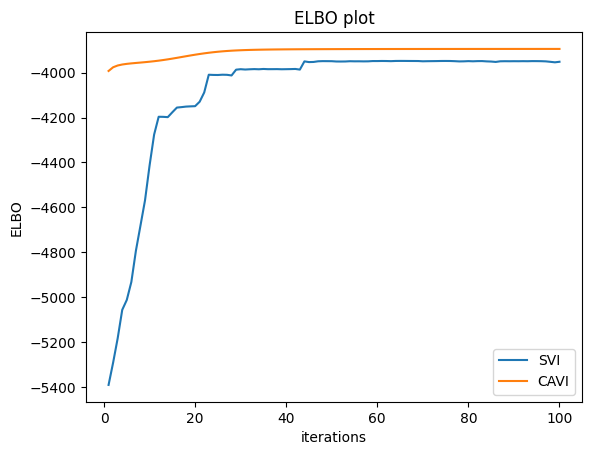

In [9]:
plt.plot(list(range(1, n_iter_cavi1 + 1)), elbo1_svi[np.arange(0, n_iter_svi1, int(n_iter_svi1 / n_iter_cavi1))], label='SVI')
plt.plot(list(range(1, n_iter_cavi1 + 1)), elbo1_cavi, label='CAVI')
plt.title("ELBO plot")
plt.xlabel("iterations")
plt.ylabel("ELBO")
plt.legend()
plt.show()

**CASE 2**

Small dataset

In [10]:
np.random.seed(0)

# Data simulation parameters
D2 = 1000
N2 = 50
K2 = 3
W2 = 10
eta_sim2 = np.ones(W2)
alpha_sim2 = np.ones(K2)

w2, z2, theta2, beta2 = generate_data(D2, N2, K2, W2, eta_sim2, alpha_sim2)

# Inference parameters
n_iter_cavi2 = 100
n_iter_svi2 = 100
eta_prior2 = np.ones(W2) * 1.
alpha_prior2 = np.ones(K2) * 1.
S2 = 100 # batch size

start_cavi2 = time.time()
phi_out2_cavi, gamma_out2_cavi, lmbda_out2_cavi, elbo2_cavi = CAVI_algorithm(w2, K2, n_iter_cavi2, eta_prior2, alpha_prior2)
end_cavi2 = time.time()

start_svi2 = time.time()
phi_out2_svi, gamma_out2_svi, lmbda_out2_svi, elbo2_svi = SVI_algorithm(w2, K2, S2, n_iter_svi2, eta_prior2, alpha_prior2)
end_svi2 = time.time()

final_phi2_cavi = phi_out2_cavi[-1]
final_gamma2_cavi = gamma_out2_cavi[-1]
final_lmbda2_cavi = lmbda_out2_cavi[-1]
final_phi2_svi = phi_out2_svi[-1]
final_gamma2_svi = gamma_out2_svi[-1]
final_lmbda2_svi = lmbda_out2_svi[-1]

**Evaluation**

Do not expect perfect results in terms expectations being identical to the "true" theta and beta. Do not expect the ELBO plot of your SVI alg to be the same as the CAVI alg. However, it should increase and be in the same ball park as that of the CAVI alg.

In [11]:
np.set_printoptions(formatter={'float': lambda x: "{0:0.3f}".format(x)})
print(f"----- Recall label switching - compare E[theta] and true theta and check for label switching -----")
print(f"E[theta] of doc 0 SVI:      {final_gamma2_svi[0] / np.sum(final_gamma2_svi[0], axis=0, keepdims=True)}")
print(f"E[theta] of doc 0 CAVI:     {final_gamma2_cavi[0] / np.sum(final_gamma2_cavi[0], axis=0, keepdims=True)}")
print(f"True theta of doc 0:        {theta2[0]}")

print(f"----- Recall label switching - e.g. E[beta_0] could be fit to true theta_1. -----")
print(f"E[beta] k=0:    {final_lmbda2_svi[0, :] / np.sum(final_lmbda2_svi[0, :], axis=-1, keepdims=True)}")
print(f"E[beta] k=1:    {final_lmbda2_svi[1, :] / np.sum(final_lmbda2_svi[1, :], axis=-1, keepdims=True)}")
print(f"E[beta] k=2:    {final_lmbda2_svi[2, :] / np.sum(final_lmbda2_svi[2, :], axis=-1, keepdims=True)}")
print(f"True beta k=0:  {beta2[0, :]}")
print(f"True beta k=1:  {beta2[1, :]}")
print(f"True beta k=2:  {beta2[2, :]}")

print(f"Time SVI: {end_svi2 - start_svi2}")
print(f"Time CAVI: {end_cavi2 - start_cavi2}")

----- Recall label switching - compare E[theta] and true theta and check for label switching -----
E[theta] of doc 0 SVI:      [0.346 0.346 0.308]
E[theta] of doc 0 CAVI:     [0.262 0.242 0.496]
True theta of doc 0:        [0.240 0.126 0.634]
----- Recall label switching - e.g. E[beta_0] could be fit to true theta_1. -----
E[beta] k=0:    [0.021 0.065 0.109 0.116 0.317 0.038 0.117 0.085 0.028 0.103]
E[beta] k=1:    [0.077 0.137 0.231 0.026 0.045 0.123 0.103 0.096 0.010 0.152]
E[beta] k=2:    [0.108 0.193 0.053 0.239 0.044 0.022 0.044 0.093 0.122 0.083]
True beta k=0:  [0.162 0.046 0.036 0.089 0.121 0.112 0.164 0.051 0.072 0.147]
True beta k=1:  [0.004 0.242 0.185 0.247 0.046 0.076 0.089 0.029 0.023 0.061]
True beta k=2:  [0.031 0.102 0.173 0.053 0.239 0.002 0.012 0.189 0.062 0.137]
Time SVI: 7.148973226547241
Time CAVI: 64.91802310943604


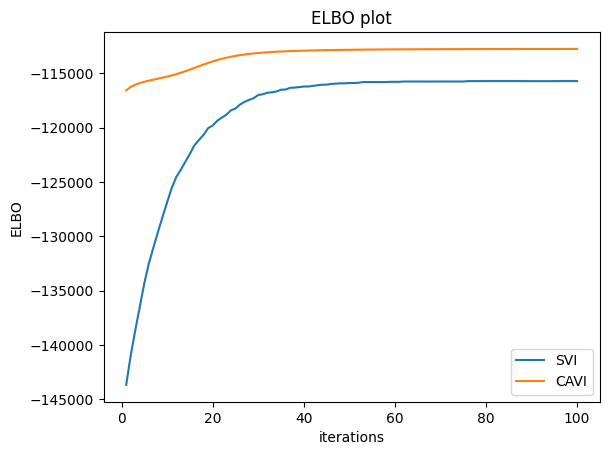

In [12]:
plt.plot(list(range(1, n_iter_cavi2 + 1)), elbo2_svi[np.arange(0, n_iter_svi2, int(n_iter_svi2 / n_iter_cavi2))], label='SVI')
plt.plot(list(range(1, n_iter_cavi2 + 1)), elbo2_cavi, label='CAVI')
plt.title("ELBO plot")
plt.xlabel("iterations")
plt.ylabel("ELBO")
plt.legend()
plt.show()

**CASE 3**

Medium small dataset, one iteration for time analysis.

In [13]:
np.random.seed(0)

# Data simulation parameters
D3 = 10**4
N3 = 500
K3 = 5
W3 = 10
eta_sim3 = np.ones(W3)
alpha_sim3 = np.ones(K3)

w3, z3, theta3, beta3 = generate_data(D3, N3, K3, W3, eta_sim3, alpha_sim3)

# Inference parameters
n_iter3 = 1
eta_prior3 = np.ones(W3) * 1.
alpha_prior3 = np.ones(K3) * 1.
S3 = 100 # batch size

start_cavi3 = time.time()
phi_out3_cavi, gamma_out3_cavi, lmbda_out3_cavi, elbo3_cavi = CAVI_algorithm(w3, K3, n_iter3, eta_prior3, alpha_prior3)
end_cavi3 = time.time()

start_svi3 = time.time()
phi_out3_svi, gamma_out3_svi, lmbda_out3_svi, elbo3_svi = SVI_algorithm(w3, K3, S3, n_iter3, eta_prior3, alpha_prior3)
end_svi3 = time.time()

final_phi3_cavi = phi_out3_cavi[-1]
final_gamma3_cavi = gamma_out3_cavi[-1]
final_lmbda3_cavi = lmbda_out3_cavi[-1]
final_phi3_svi = phi_out3_svi[-1]
final_gamma3_svi = gamma_out3_svi[-1]
final_lmbda3_svi = lmbda_out3_svi[-1]

In [14]:
print(f"Examine per iteration run time.")
print(f"Time SVI: {end_svi3 - start_svi3}")
print(f"Time CAVI: {end_cavi3 - start_cavi3}")

Examine per iteration run time.
Time SVI: 2.8195762634277344
Time CAVI: 84.12021613121033
